## 1. Imports

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

print("Libraries imported.")

Libraries imported.


## 2. Paths and version

In [2]:
PROJECT_DIR = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project")
SOURCE_CSV  = PROJECT_DIR / "processed_10hz" / "clean_dataset_final_v2.csv"
DATA_VERSION = "v5_voltage_kfold5"
OUTPUT_ROOT  = PROJECT_DIR / "processed_10hz" / "v2"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

PLOT_DIR = OUTPUT_ROOT / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)
OVERWRITE = True

print(f"Source   : {SOURCE_CSV}")
print(f"Output   : {OUTPUT_ROOT}")
print(f"Plots    : {PLOT_DIR}")
print(f"Overwrite: {OVERWRITE}")

Source   : /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/processed_10hz/clean_dataset_final_v2.csv
Output   : /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/processed_10hz/v2
Plots    : /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/processed_10hz/v2/plots
Overwrite: True


## 3. Save helpers

In [3]:
def safe_to_parquet(df, path, index=False):
    path = Path(path)
    if path.exists() and not OVERWRITE:
        raise FileExistsError(f"File exists and OVERWRITE=False:\n{path}")
    df.to_parquet(path, index=index)
    print(f"  Saved: {path.name}  {df.shape}")

def safe_json_dump(obj, path):
    path = Path(path)
    if path.exists() and not OVERWRITE:
        raise FileExistsError(f"File exists and OVERWRITE=False:\n{path}")
    with open(path, "w") as f:
        json.dump(obj, f, indent=4)
    print(f"  Saved: {path.name}")

## 4. Load clean dataset from notebook 01

In [4]:
if not SOURCE_CSV.exists():
    raise FileNotFoundError(
        f"Source CSV not found:\n{SOURCE_CSV}\n"
        "Run notebook 01 first to generate this file."
    )

full_df = pd.read_csv(SOURCE_CSV, low_memory=False)

print(f"Loaded: {full_df.shape}")
print(f"Flights: {full_df['log_id'].nunique()}")
print(full_df["dataset_label"].value_counts())
print(f"\nColumns: {full_df.columns.tolist()}")

print("\nNew feature check:")
for feat in ["is_idle", "power_w_rolling_std_3s"]:
    status = "✓" if feat in full_df.columns else "✗ MISSING — rerun notebook 01"
    print(f"  {feat}: {status}")

Loaded: (971822, 16)
Flights: 168
dataset_label
normal      690380
abnormal    281442
Name: count, dtype: int64

Columns: ['log_id', 'dataset_label', 'battery_status__cell_count', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__voltage_filtered_v', 'battery_status__voltage_v', 'cumulative_energy_wh', 'power_w', 'time_s', 'is_idle', 'power_w_rolling_std_3s', 'target_energy_next_60s_wh']

New feature check:
  is_idle: ✓
  power_w_rolling_std_3s: ✓


## 5. Target and feature definitions

In [5]:
TARGET_COL = "target_energy_next_60s_wh"

NON_FEATURE_COLS = ["log_id", "dataset_label", TARGET_COL]

assert TARGET_COL in full_df.columns, f"Target column missing: {TARGET_COL}"
print(f"Target: {TARGET_COL}")
print(f"Target range: {full_df[TARGET_COL].min():.4f} – {full_df[TARGET_COL].max():.4f} Wh")

Target: target_energy_next_60s_wh
Target range: 0.0000 – 27.5020 Wh


## 6. Add voltage quality features


### 1. cell_count=0 in f53dabf1 causes division-by-zero
### 2. repair function needs to run per-split using training medians only

In [6]:


def add_battery_voltage_quality_flags(df):
    df = df.copy()
    # replace 0 with NaN to avoid division by zero
    cell_count_safe = df["battery_status__cell_count"].replace(0, np.nan)

    df["voltage_per_cell"] = (
        df["battery_status__voltage_v"] / cell_count_safe
    )
    df["voltage_filtered_per_cell"] = (
        df["battery_status__voltage_filtered_v"] / cell_count_safe
    )

    # flag rows outside LiPo plausible range
    # <2.5V = deep discharge or fault, >4.35V = overcharge or fault
    df["voltage_per_cell_suspicious"] = (
        (df["voltage_per_cell"] < 2.5) |
        (df["voltage_per_cell"] > 4.35) |
        (df["voltage_per_cell"].isna()) |
        (df["voltage_filtered_per_cell"] < 2.5) |
        (df["voltage_filtered_per_cell"] > 4.35) |
        (df["voltage_filtered_per_cell"].isna())
    ).astype(int)

    return df

full_df = add_battery_voltage_quality_flags(full_df)

print("Voltage features added:")
print(f"  voltage_per_cell          : {full_df['voltage_per_cell'].isna().sum():,} NaN")
print(f"  voltage_filtered_per_cell : {full_df['voltage_filtered_per_cell'].isna().sum():,} NaN")
print(f"  voltage_per_cell_suspicious: {full_df['voltage_per_cell_suspicious'].sum():,} flagged")
print("\nSuspicious % by label:")
print((full_df.groupby("dataset_label")["voltage_per_cell_suspicious"].mean()*100).round(2))

Voltage features added:
  voltage_per_cell          : 4,897 NaN
  voltage_filtered_per_cell : 4,897 NaN
  voltage_per_cell_suspicious: 108,213 flagged

Suspicious % by label:
dataset_label
abnormal     4.26
normal      13.94
Name: voltage_per_cell_suspicious, dtype: float64


## 7. Exclude sensor fault flight

### f53dabf1 has cell_count=0 for all 4897 rows
### voltage_per_cell flags it automatically (100% suspicious rows)
### excluded as data quality issue — full justification in notebook 05d

In [7]:


EXCLUDE_FLIGHT_IDS = ["f53dabf1-a0fb-433e-8ba8-f09c569db684"]

flights_before = full_df["log_id"].nunique()
rows_before    = len(full_df)

full_df = full_df[~full_df["log_id"].isin(EXCLUDE_FLIGHT_IDS)].reset_index(drop=True)

print("=" * 60)
print("SENSOR FAULT FLIGHT EXCLUDED")
print("=" * 60)
print(f"Flights before : {flights_before}")
print(f"Flights after  : {full_df['log_id'].nunique()}")
print(f"Rows removed   : {rows_before - len(full_df):,}")
print(f"Excluded ID    : {EXCLUDE_FLIGHT_IDS[0]}")
print(f"Reason         : cell_count=0 throughout, voltage/cell=10.27V (impossible)")

assert EXCLUDE_FLIGHT_IDS[0] not in full_df["log_id"].values, \
    "ERROR: excluded flight still in dataset"
print("\nExclusion verified ✓")

SENSOR FAULT FLIGHT EXCLUDED
Flights before : 168
Flights after  : 167
Rows removed   : 4,897
Excluded ID    : f53dabf1-a0fb-433e-8ba8-f09c569db684
Reason         : cell_count=0 throughout, voltage/cell=10.27V (impossible)

Exclusion verified ✓


## 9. Label consistency check

In [8]:
label_check = full_df.groupby("log_id")["dataset_label"].nunique()
assert label_check.max() == 1, "Some flights have mixed labels"
print("Label consistency check passed")

flight_table = (
    full_df.groupby("log_id")["dataset_label"]
    .first()
    .reset_index()
)

print(f"\nTotal flights: {len(flight_table)}")
print(flight_table["dataset_label"].value_counts())

Label consistency check passed

Total flights: 167
dataset_label
normal      126
abnormal     41
Name: count, dtype: int64


## 10. Missing value report

#### check missingness before splitting — for documentation only
#### imputation will happen per-split to avoid leakage

In [9]:


feature_cols_all = [
    c for c in full_df.columns
    if c not in NON_FEATURE_COLS
    and pd.api.types.is_numeric_dtype(full_df[c])
]

missing_report = pd.DataFrame({
    "feature"         : feature_cols_all,
    "missing_count"   : full_df[feature_cols_all].isna().sum().values,
    "missing_percent" : full_df[feature_cols_all].isna().mean().values * 100,
}).sort_values("missing_percent", ascending=False).reset_index(drop=True)

print(f"Features with any missing: {(missing_report['missing_percent']>0).sum()}")
print(f"Features 0% missing      : {(missing_report['missing_percent']==0).sum()}")
display(missing_report.head(30))

missing_report.to_csv(OUTPUT_ROOT / "missing_value_report_pre_split.csv", index=False)

Features with any missing: 0
Features 0% missing      : 16


,feature,missing_count,missing_percent
0,battery_status__cell_count,0,0.0
1,battery_status__current_a,0,0.0
2,battery_status__current_filtered_a,0,0.0
3,battery_status__discharged_mah,0,0.0
4,battery_status__remaining,0,0.0
5,battery_status__scale,0,0.0
6,battery_status__voltage_filtered_v,0,0.0
7,battery_status__voltage_v,0,0.0
8,cumulative_energy_wh,0,0.0
9,power_w,0,0.0


## 11. Structural missingness check (cell voltage columns)

In [ ]:
cell_voltage_cols = [
    "battery_status__voltage_cell_v[0]",
    "battery_status__voltage_cell_v[1]",
    "battery_status__voltage_cell_v[2]",
    "battery_status__voltage_cell_v[3]",
]

cell_voltage_cols = [c for c in cell_voltage_cols if c in full_df.columns]

if cell_voltage_cols:
    structural_report = []
    for col in cell_voltage_cols:
        per_flight = (
            full_df.groupby("log_id")[col]
            .agg(
                total_rows="size",
                missing_rows=lambda x: x.isna().sum(),
                observed_rows=lambda x: x.notna().sum()
            )
        )
        structural_report.append({
            "feature"                   : col,
            "fully_missing_flights"     : ((per_flight["missing_rows"]>0) & (per_flight["observed_rows"]==0)).sum(),
            "partially_missing_flights" : ((per_flight["missing_rows"]>0) & (per_flight["observed_rows"]>0)).sum(),
            "fully_observed_flights"    : ((per_flight["missing_rows"]==0)).sum(),
            "overall_missing_%"         : full_df[col].isna().mean()*100
        })
    display(pd.DataFrame(structural_report))
else:
    print("Cell voltage columns already removed upstream")

Cell voltage columns already removed upstream ✓


## 12. Final feature list

In [11]:


feature_cols = [
    c for c in full_df.columns
    if c not in NON_FEATURE_COLS
    and pd.api.types.is_numeric_dtype(full_df[c])
]

# replace inf with NaN
full_df[feature_cols] = full_df[feature_cols].replace([np.inf, -np.inf], np.nan)

print(f"Final feature count: {len(feature_cols)}")
for i, col in enumerate(feature_cols, 1):
    print(f"  {i:2d}. {col}")

Final feature count: 16
   1. battery_status__cell_count
   2. battery_status__current_a
   3. battery_status__current_filtered_a
   4. battery_status__discharged_mah
   5. battery_status__remaining
   6. battery_status__scale
   7. battery_status__voltage_filtered_v
   8. battery_status__voltage_v
   9. cumulative_energy_wh
  10. power_w
  11. time_s
  12. is_idle
  13. power_w_rolling_std_3s
  14. voltage_per_cell
  15. voltage_filtered_per_cell
  16. voltage_per_cell_suspicious


## 13. Timeseries plot of one representative normal flight

Selected flight: 42b57f46-f2fe-45a4-8a31-928db553fb28
Rows: 23914  Duration: 2391s


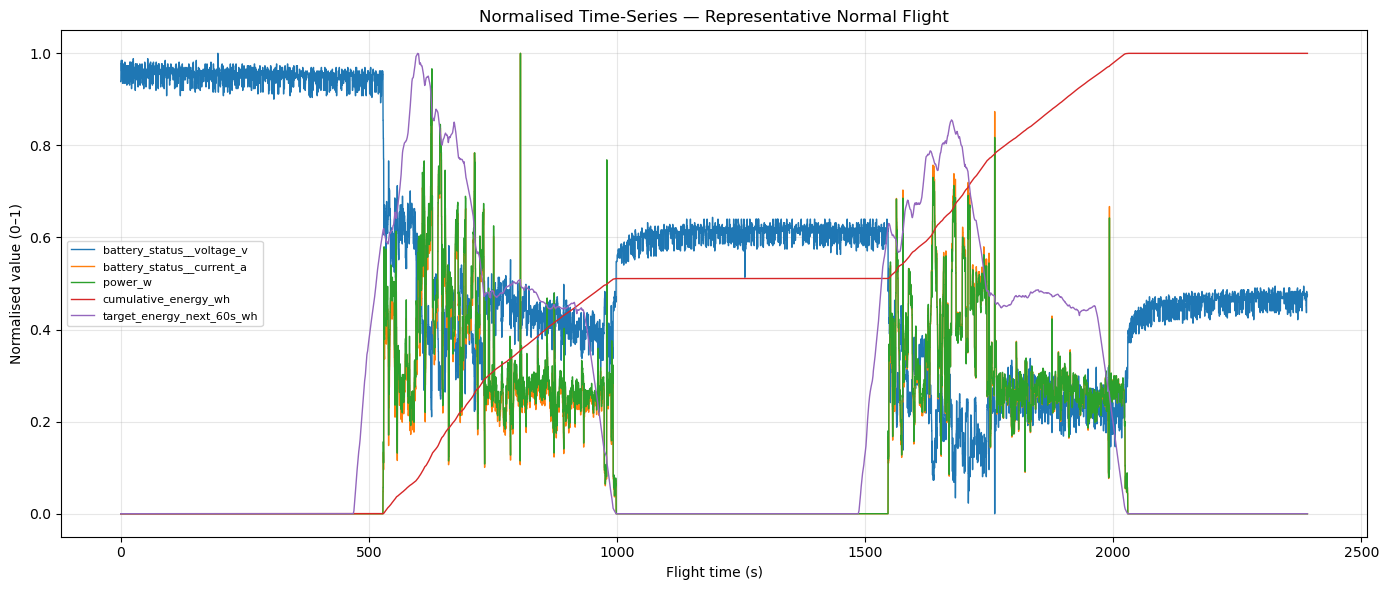

In [12]:
timeseries_features = [
    "battery_status__voltage_v",
    "battery_status__current_a",
    "power_w",
    "cumulative_energy_wh",
    TARGET_COL
]
timeseries_features = [c for c in timeseries_features if c in full_df.columns]

# pick longest normal flight
normal_flights = (
    full_df[full_df["dataset_label"]=="normal"]
    .groupby("log_id").size()
    .sort_values(ascending=False)
)
selected_flight_id = normal_flights.index[0]
flight_plot_df = (
    full_df[full_df["log_id"]==selected_flight_id]
    .sort_values("time_s").copy()
)

print(f"Selected flight: {selected_flight_id}")
print(f"Rows: {len(flight_plot_df)}  Duration: {flight_plot_df['time_s'].max():.0f}s")

# normalised time-series — for visualisation only
plot_df = flight_plot_df[["time_s"] + timeseries_features].copy()
for col in timeseries_features:
    lo, hi = plot_df[col].min(), plot_df[col].max()
    plot_df[col] = (plot_df[col]-lo)/(hi-lo) if hi != lo else 0.0

plt.figure(figsize=(14, 6))
for col in timeseries_features:
    plt.plot(plot_df["time_s"], plot_df[col], label=col, linewidth=1)
plt.title("Normalised Time-Series — Representative Normal Flight")
plt.xlabel("Flight time (s)")
plt.ylabel("Normalised value (0–1)")
plt.legend(fontsize=8)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(PLOT_DIR / "timeseries_normal_flight.png", dpi=150)
plt.show()

## 14. Normal vs abnormal time-series comparison

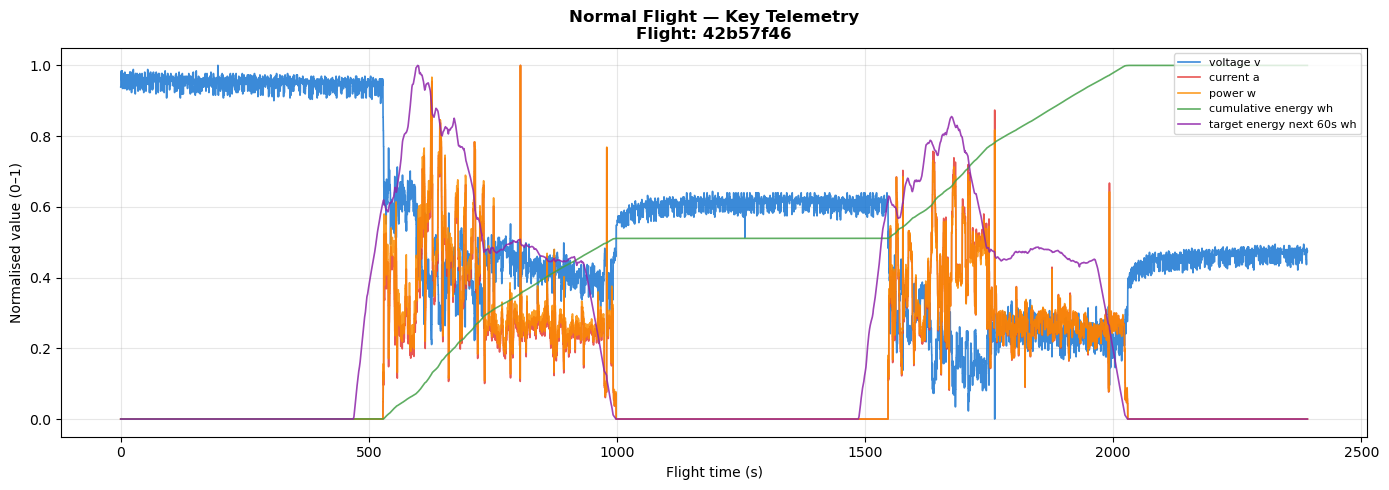

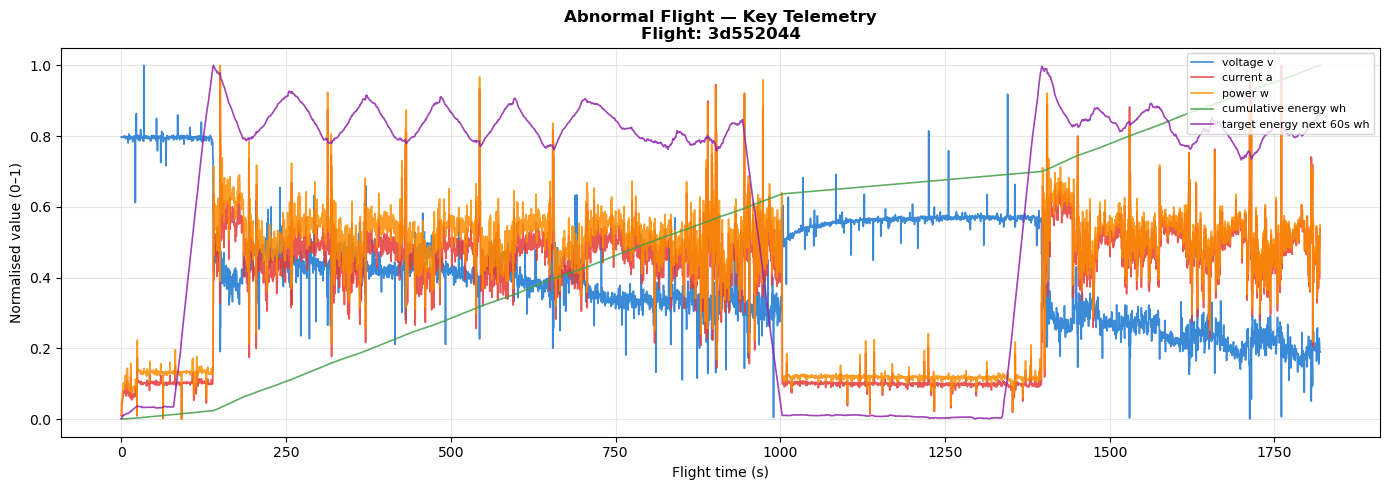

In [13]:
def plot_normalised_timeseries(flight_df, title, save_name):
    plot_df = flight_df[["time_s"] + timeseries_features].copy()
    for col in timeseries_features:
        lo, hi = plot_df[col].min(), plot_df[col].max()
        plot_df[col] = (plot_df[col]-lo)/(hi-lo) if hi != lo else 0.0

    colors = ["#1976D2","#E53935","#FB8C00","#43A047","#8E24AA"]
    fig, ax = plt.subplots(figsize=(14, 5))
    for col, color in zip(timeseries_features, colors):
        ax.plot(plot_df["time_s"], plot_df[col],
                label=col.replace("battery_status__","").replace("_"," "),
                linewidth=1.2, color=color, alpha=0.85)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Flight time (s)", fontsize=10)
    ax.set_ylabel("Normalised value (0–1)", fontsize=10)
    ax.legend(fontsize=8, loc="upper right")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f"{save_name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

# pick longest abnormal flight
abnormal_id = (
    full_df[full_df["dataset_label"]=="abnormal"]
    .groupby("log_id").size()
    .sort_values(ascending=False)
    .index[0]
)
abnormal_plot_df = full_df[full_df["log_id"]==abnormal_id].sort_values("time_s").copy()

plot_normalised_timeseries(
    flight_plot_df,
    title=f"Normal Flight — Key Telemetry\nFlight: {selected_flight_id[:8]}",
    save_name="timeseries_normal_flight_v2"
)
plot_normalised_timeseries(
    abnormal_plot_df,
    title=f"Abnormal Flight — Key Telemetry\nFlight: {abnormal_id[:8]}",
    save_name="timeseries_abnormal_flight"
)

## 15. Normal vs abnormal flight progress profiles

Highest correlated feature: power_w (0.9557)


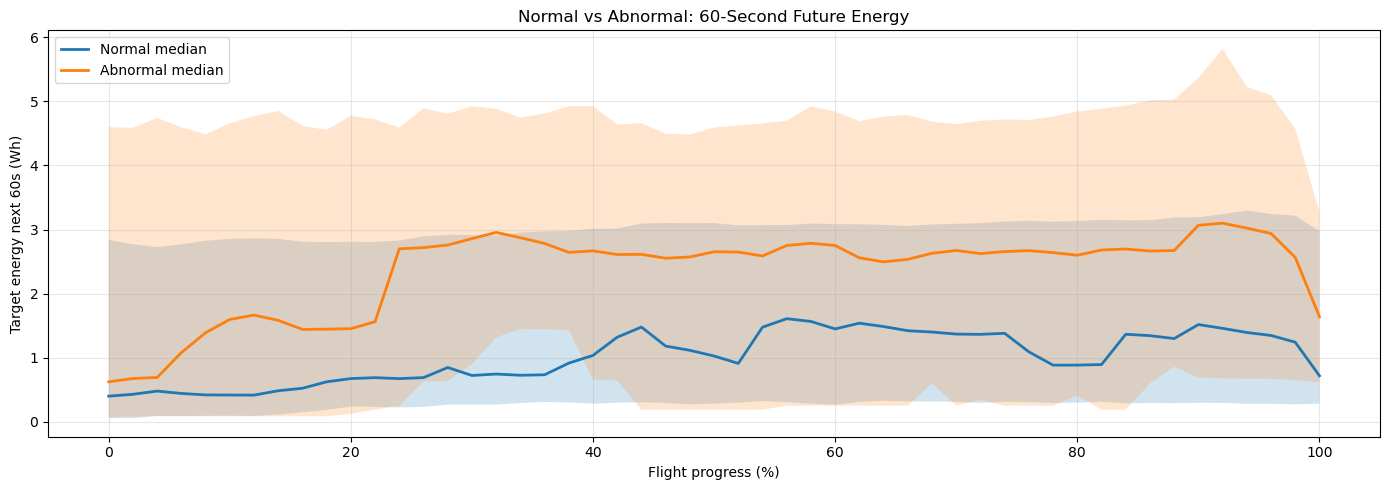

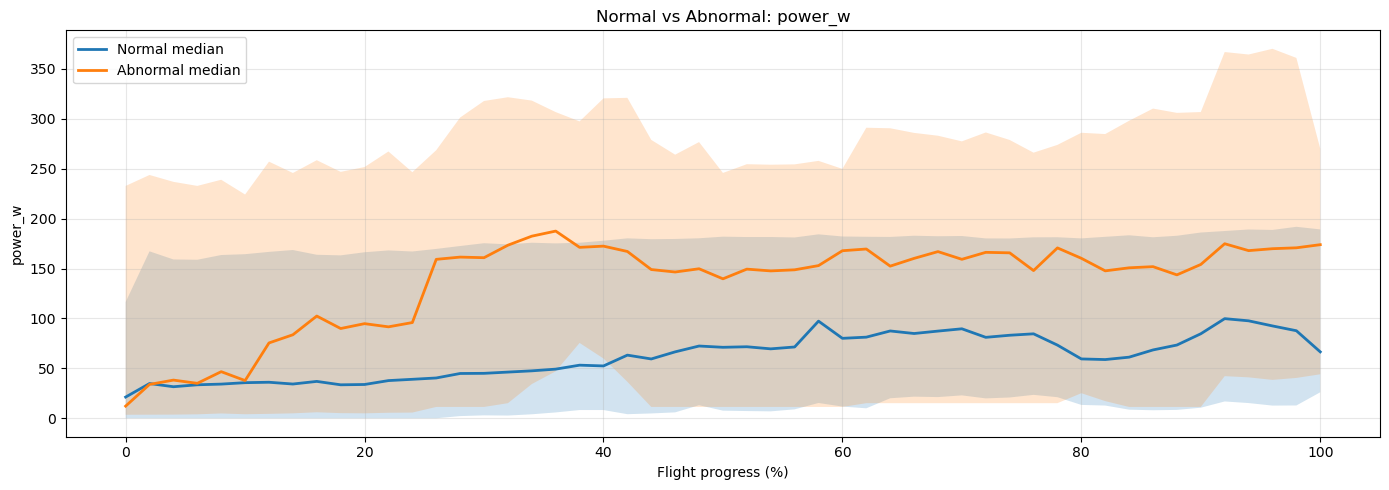

In [14]:
plot_data = full_df.copy()
plot_data["log_id"] = plot_data["log_id"].astype(str)

flight_duration = (
    plot_data.groupby("log_id")["time_s"].max().rename("flight_duration_s")
)
plot_data = plot_data.merge(flight_duration, on="log_id", how="left")
plot_data["flight_progress_pct"] = (
    plot_data["time_s"] / plot_data["flight_duration_s"]
) * 100
plot_data = plot_data[plot_data["flight_progress_pct"].between(0, 100)].copy()
plot_data["progress_bin"] = (plot_data["flight_progress_pct"] // 2 * 2).astype(int)


def plot_normal_abnormal_profile(data, value_col, y_label, title):
    summary = (
        data.groupby(["dataset_label","progress_bin"])[value_col]
        .agg(median="median",
             q25=lambda x: x.quantile(0.25),
             q75=lambda x: x.quantile(0.75))
        .reset_index()
    )
    plt.figure(figsize=(14, 5))
    for label in ["normal","abnormal"]:
        temp = summary[summary["dataset_label"]==label]
        if temp.empty: continue
        plt.plot(temp["progress_bin"], temp["median"],
                 linewidth=2, label=f"{label.capitalize()} median")
        plt.fill_between(temp["progress_bin"], temp["q25"], temp["q75"], alpha=0.2)
    plt.xlabel("Flight progress (%)")
    plt.ylabel(y_label)
    plt.title(title)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f"profile_{value_col[:20]}.png", dpi=150)
    plt.show()

# correlation to find highest-correlated feature
correlations = (
    full_df[feature_cols + [TARGET_COL]]
    .corr(numeric_only=True)[TARGET_COL]
    .drop(TARGET_COL).abs()
    .sort_values(ascending=False)
)
highest_corr_feature = correlations.index[0]
print(f"Highest correlated feature: {highest_corr_feature} ({correlations.iloc[0]:.4f})")

plot_normal_abnormal_profile(
    plot_data, TARGET_COL,
    "Target energy next 60s (Wh)",
    "Normal vs Abnormal: 60-Second Future Energy"
)
plot_normal_abnormal_profile(
    plot_data, highest_corr_feature,
    highest_corr_feature,
    f"Normal vs Abnormal: {highest_corr_feature}"
)

## 16. Voltage repair function

In [15]:
def repair_voltage_features_before_scaling(train_df, val_df, test_df, split_name):
    train_df = train_df.copy()
    val_df   = val_df.copy()
    test_df  = test_df.copy()

    voltage_cols = ["voltage_per_cell", "voltage_filtered_per_cell"]

    # step 1: log how many rows need repair (do NOT set flag yet)
    for df_name, df in [("Train",train_df),("Val",val_df),("Test",test_df)]:
        missing = df[voltage_cols].isna().any(axis=1)
        if missing.any():
            print(f"  {split_name} | {df_name}: {missing.sum():,} rows need repair")

    def interpolate_within_flights(df, df_name):
        df = df.copy()
        df["_order"] = np.arange(len(df))
        df = df.sort_values(["log_id","time_s"]).reset_index(drop=True)

        before = int(df[voltage_cols].isna().sum().sum())
        for col in voltage_cols:
            df[col] = (
                df.groupby("log_id")[col]
                .transform(lambda s:
                    s.interpolate(method="linear", limit_direction="both")
                     .ffill().bfill()
                )
            )
        after = int(df[voltage_cols].isna().sum().sum())
        print(f"  {split_name} | {df_name}: NaN {before} → {after} after interpolation")

        df = df.sort_values("_order").reset_index(drop=True).drop(columns=["_order"])
        return df

    train_df = interpolate_within_flights(train_df, "Train")
    val_df   = interpolate_within_flights(val_df,   "Val")
    test_df  = interpolate_within_flights(test_df,  "Test")

    # step 2: fallback to training-only medians for anything still missing
    train_medians = {col: train_df[col].median() for col in voltage_cols}
    for col in voltage_cols:
        if train_df[col].isna().sum() > 0:
            train_df[col] = train_df[col].fillna(train_medians[col])
            val_df[col]   = val_df[col].fillna(train_medians[col])
            test_df[col]  = test_df[col].fillna(train_medians[col])
            print(f"  Fallback median for {col}: {train_medians[col]:.4f}")

    # step 3: set suspicious flag from POST-repair status
    # 1 = repair failed (still NaN), 0 = successfully repaired or was never NaN
    # step 3: restore physics-based suspicious flag after interpolation
    # re-apply the same LiPo plausibility range used in Section 6
    # (2.5V–4.35V per cell). Interpolation may have filled NaNs with
    # in-range values, so the flag must be recomputed from actual values,
    # not from whether NaNs remain.
    for df in [train_df, val_df, test_df]:
        df["voltage_per_cell_suspicious"] = (
            (df["voltage_per_cell"] < 2.5) |
            (df["voltage_per_cell"] > 4.35) |
            (df["voltage_per_cell"].isna()) |
            (df["voltage_filtered_per_cell"] < 2.5) |
            (df["voltage_filtered_per_cell"] > 4.35) |
            (df["voltage_filtered_per_cell"].isna())
        ).astype(int)

    return train_df, val_df, test_df

## 17. 5-fold stratified cross-validation at the flight level

In [16]:
# Each of the 167 flights appears in exactly one test fold.
# Stratification preserves the ~75/25 normal-abnormal ratio across folds.

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
summary_records = []

for fold_idx, (train_val_idx, test_idx) in enumerate(
    skf.split(flight_table, flight_table["dataset_label"]), start=1
):
    split_name = f"fold_{fold_idx:02d}"
    split_dir  = OUTPUT_ROOT / split_name
    split_dir.mkdir(parents=True, exist_ok=True)

    print("\n" + "="*70)
    print(f"FOLD: {split_name}")
    print("="*70)

    # carve out test fold — these flights are completely held out
    test_flights  = flight_table.iloc[test_idx]

    # split the remaining flights into train / val (85% / 15%)
    # stratified so the normal-abnormal ratio is maintained in both
    train_val_flights = flight_table.iloc[train_val_idx]
    train_flights, val_flights = train_test_split(
        train_val_flights,
        test_size=0.15,
        stratify=train_val_flights["dataset_label"],
        random_state=42
    )

    train_ids = set(train_flights["log_id"])
    val_ids   = set(val_flights["log_id"])
    test_ids  = set(test_flights["log_id"])

    # hard check — no flight should ever appear in more than one partition
    assert len(train_ids & val_ids)  == 0, "Train/Val overlap!"
    assert len(train_ids & test_ids) == 0, "Train/Test overlap!"
    assert len(val_ids   & test_ids) == 0, "Val/Test overlap!"

    # also confirm every flight in the dataset is accounted for
    assert len(train_ids | val_ids | test_ids) == len(flight_table), \
        "Some flights are missing from this fold!"

    split_train = full_df[full_df["log_id"].isin(train_ids)].copy()
    split_val   = full_df[full_df["log_id"].isin(val_ids)].copy()
    split_test  = full_df[full_df["log_id"].isin(test_ids)].copy()

    print(f"Train: {split_train.shape} | {split_train['log_id'].nunique()} flights")
    print(f"Val  : {split_val.shape}   | {split_val['log_id'].nunique()} flights")
    print(f"Test : {split_test.shape}  | {split_test['log_id'].nunique()} flights")

    # repair voltage features using training medians only — no leakage
    split_train, split_val, split_test = repair_voltage_features_before_scaling(
        split_train, split_val, split_test, split_name
    )

    # replace any inf values before scaling
    for df in [split_train, split_val, split_test]:
        df[feature_cols] = df[feature_cols].replace([np.inf, -np.inf], np.nan)

    # final NaN check before scaling
    for df_name, df in [("Train", split_train), ("Val", split_val), ("Test", split_test)]:
        nan_count = df[feature_cols].isna().sum().sum()
        assert nan_count == 0, f"{split_name} | {df_name}: {nan_count} NaNs remain before scaling"
    print("Pre-scale NaN check passed ✓")

    # missing value report for this fold
    missing_pre = pd.DataFrame({
        "feature"          : feature_cols,
        "train_missing_%"  : split_train[feature_cols].isna().mean().values * 100,
        "val_missing_%"    : split_val[feature_cols].isna().mean().values * 100,
        "test_missing_%"   : split_test[feature_cols].isna().mean().values * 100,
    }).sort_values("train_missing_%", ascending=False)
    missing_pre.to_csv(split_dir / f"missing_value_report_{split_name}.csv", index=False)

    # ── save unscaled (imputed) parquets — used by tree-based models ─────────
    file_interp = f"no_dr_interpolated_{DATA_VERSION}_{split_name}"
    for tag, df in [("train", split_train), ("val", split_val), ("test", split_test)]:
        safe_to_parquet(
            pd.concat([
                df[["log_id", "dataset_label"]].reset_index(drop=True),
                df[feature_cols].reset_index(drop=True),
                df[[TARGET_COL]].reset_index(drop=True)
            ], axis=1),
            split_dir / f"{tag}_{file_interp}.parquet"
        )

    # ── fit scaler on normal training rows only — prevents anomaly signal ─────
    # leaking into the scale parameters
    scaler = StandardScaler()
    normal_train = split_train[split_train["dataset_label"] == "normal"]
    scaler.fit(normal_train[feature_cols])

    X_train_scaled = scaler.transform(split_train[feature_cols])
    X_val_scaled   = scaler.transform(split_val[feature_cols])
    X_test_scaled  = scaler.transform(split_test[feature_cols])

    # quick sanity check on the scaled training set
    scale_check = pd.DataFrame(X_train_scaled, columns=feature_cols)
    max_mean    = scale_check.mean().abs().max()
    min_std     = scale_check.std().min()
    print(f"Scale check — max |mean| = {max_mean:.4f}  |  min std = {min_std:.4f}")

    pd.DataFrame({
        "feature"           : feature_cols,
        "scaled_train_mean" : scale_check.mean().values,
        "scaled_train_std"  : scale_check.std().values,
    }).to_csv(split_dir / f"scaling_check_{split_name}.csv", index=False)

    # ── save scaled parquets — used by LSTM / BiLSTM / anomaly detection ─────
    file_scaled = f"no_dr_scaled_{DATA_VERSION}_{split_name}"
    scaled_sets = [
        ("train", split_train, X_train_scaled),
        ("val",   split_val,   X_val_scaled),
        ("test",  split_test,  X_test_scaled),
    ]
    for tag, df_meta, X_scaled in scaled_sets:
        safe_to_parquet(
            pd.concat([
                df_meta[["log_id", "dataset_label"]].reset_index(drop=True),
                pd.DataFrame(X_scaled, columns=feature_cols),
                df_meta[[TARGET_COL]].reset_index(drop=True)
            ], axis=1),
            split_dir / f"{tag}_{file_scaled}.parquet"
        )

    # ── save scaler artefacts for reproducibility ─────────────────────────────
    joblib.dump(scaler, split_dir / f"scaler_{split_name}.joblib")
    safe_json_dump(feature_cols, split_dir / f"feature_cols_{split_name}.json")

    pd.DataFrame({
        "feature"    : feature_cols,
        "train_mean" : scaler.mean_,
        "train_std"  : scaler.scale_,
        "train_var"  : scaler.var_,
    }).to_csv(split_dir / f"scaler_params_{split_name}.csv", index=False)
    print(f"Scaler params saved: {len(feature_cols)} features")

    # ── final dataset summary ─────────────────────────────────────────────────
    def check_dataset(name, df_meta, X_scaled, y):
        print(f"\n  {name}:")
        print(f"    Rows     : {len(df_meta):,}  |  Features: {X_scaled.shape[1]}")
        print(f"    Flights  : {df_meta['log_id'].nunique()}")
        print(f"    Target missing: {y.isna().sum()}")
        print(f"    Labels   : {dict(df_meta['dataset_label'].value_counts())}")

    check_dataset("Train", split_train, X_train_scaled, split_train[TARGET_COL])
    check_dataset("Val",   split_val,   X_val_scaled,   split_val[TARGET_COL])
    check_dataset("Test",  split_test,  X_test_scaled,  split_test[TARGET_COL])

    summary_records.append({
        "split_name"     : split_name,
        "fold"           : fold_idx,
        "train_flights"  : split_train["log_id"].nunique(),
        "val_flights"    : split_val["log_id"].nunique(),
        "test_flights"   : split_test["log_id"].nunique(),
        "train_rows"     : len(split_train),
        "val_rows"       : len(split_val),
        "test_rows"      : len(split_test),
        "n_features"     : len(feature_cols),
        "train_normal"   : (split_train["dataset_label"] == "normal").sum(),
        "train_abnormal" : (split_train["dataset_label"] == "abnormal").sum(),
        "test_normal"    : (split_test["dataset_label"] == "normal").sum(),
        "test_abnormal"  : (split_test["dataset_label"] == "abnormal").sum(),
    })
    print(f"\n{split_name} complete ✓")


print("ALL 5 FOLDS COMPLETE")


FOLD: fold_01
Train: (665216, 19) | 113 flights
Val  : (110878, 19)   | 20 flights
Test : (190831, 19)  | 34 flights
  fold_01 | Train: NaN 0 → 0 after interpolation
  fold_01 | Val: NaN 0 → 0 after interpolation
  fold_01 | Test: NaN 0 → 0 after interpolation
Pre-scale NaN check passed ✓
  Saved: train_no_dr_interpolated_v5_voltage_kfold5_fold_01.parquet  (665216, 19)
  Saved: val_no_dr_interpolated_v5_voltage_kfold5_fold_01.parquet  (110878, 19)
  Saved: test_no_dr_interpolated_v5_voltage_kfold5_fold_01.parquet  (190831, 19)
Scale check — max |mean| = 0.9965  |  min std = 0.8718
  Saved: train_no_dr_scaled_v5_voltage_kfold5_fold_01.parquet  (665216, 19)
  Saved: val_no_dr_scaled_v5_voltage_kfold5_fold_01.parquet  (110878, 19)
  Saved: test_no_dr_scaled_v5_voltage_kfold5_fold_01.parquet  (190831, 19)
  Saved: feature_cols_fold_01.json
Scaler params saved: 16 features

  Train:
    Rows     : 665,216  |  Features: 16
    Flights  : 113
    Target missing: 0
    Labels   : {'normal': n

## 18. Summary table

In [17]:
summary_df = pd.DataFrame(summary_records)
print(summary_df.to_string(index=False))
summary_df.to_csv(
    OUTPUT_ROOT / f"split_summary_{DATA_VERSION}.csv", index=False
)
print(f"\nSummary saved: {OUTPUT_ROOT}")
print(f"Features per split: {summary_df['n_features'].iloc[0]}")
print(f"New features: is_idle, power_w_rolling_std_3s")

split_name  fold  train_flights  val_flights  test_flights  train_rows  val_rows  test_rows  n_features  train_normal  train_abnormal  test_normal  test_abnormal
   fold_01     1            113           20            34      665216    110878     190831          16        466861          198355       134530          56301
   fold_02     2            113           20            34      643038    105335     218552          16        468493          174545       148698          69854
   fold_03     3            113           21            33      677953    105412     183560          16        472386          205567       131768          51792
   fold_04     4            113           21            33      671181    114458     181286          16        458193          212988       138792          42494
   fold_05     5            113           21            33      648120    126109     192696          16        459104          189016       136592          56104

Summary saved: /Users/arjun

# CNN-LSTM-AE architecture diagram

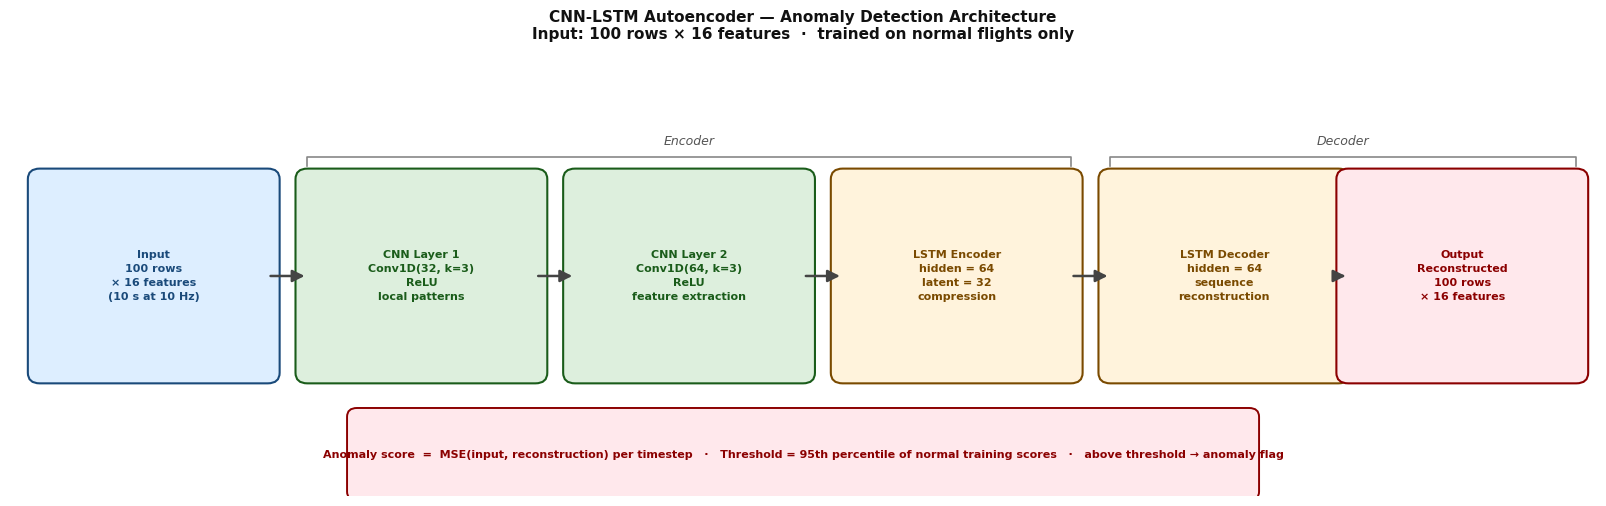

Architecture diagram saved: cnn_lstm_ae_architecture.png  (16 features)


In [21]:
n_features = len(feature_cols)

fig, ax = plt.subplots(figsize=(16, 5))
ax.set_xlim(0, 16)
ax.set_ylim(0, 5)
ax.axis("off")
fig.patch.set_facecolor("white")

BLUE   = ("#DDEEFF", "#1a4a7a")
GREEN  = ("#DDEFDD", "#1a5c1a")
AMBER  = ("#FFF3DC", "#7a4a00")
PINK   = ("#FFE8EC", "#8b0000")

# (x_left, label, color)
boxes = [
    (0.3,  f"Input\n100 rows\n× {n_features} features\n(10 s at 10 Hz)", BLUE),
    (3.0,  "CNN Layer 1\nConv1D(32, k=3)\nReLU\nlocal patterns",          GREEN),
    (5.7,  "CNN Layer 2\nConv1D(64, k=3)\nReLU\nfeature extraction",      GREEN),
    (8.4,  "LSTM Encoder\nhidden = 64\nlatent = 32\ncompression",          AMBER),
    (11.1, "LSTM Decoder\nhidden = 64\nsequence\nreconstruction",          AMBER),
    (13.5, "Output\nReconstructed\n100 rows\n× {n} features".replace("{n}", str(n_features)), PINK),
]

BOX_W = 2.3
BOX_H = 2.2
BOX_Y = 1.4
MID_Y = BOX_Y + BOX_H / 2

for x, label, (fc, tc) in boxes:
    ax.add_patch(FancyBboxPatch(
        (x, BOX_Y), BOX_W, BOX_H,
        boxstyle="round,pad=0.12",
        facecolor=fc, edgecolor=tc, linewidth=1.5, zorder=2
    ))
    ax.text(x + BOX_W / 2, MID_Y, label,
            ha="center", va="center", fontsize=8,
            fontweight="bold", color=tc, zorder=3,
            linespacing=1.5)

# arrows between boxes
arrow_gaps = [(boxes[i][0] + BOX_W, boxes[i+1][0]) for i in range(len(boxes)-1)]
for x_start, x_end in arrow_gaps:
    mid = (x_start + x_end) / 2
    ax.annotate("", xy=(x_end, MID_Y), xytext=(x_start, MID_Y),
                arrowprops=dict(arrowstyle="-|>", color="#444",
                                lw=1.8, mutation_scale=18), zorder=4)

# encoder / decoder bracket labels
for x1, x2, label in [
    (boxes[1][0], boxes[3][0] + BOX_W, "Encoder"),
    (boxes[4][0], boxes[5][0] + BOX_W, "Decoder"),
]:
    y_br = BOX_Y + BOX_H + 0.15
    ax.plot([x1, x1, x2, x2], [y_br, y_br+0.1, y_br+0.1, y_br],
            color="#888", lw=1.2)
    ax.text((x1+x2)/2, y_br+0.2, label,
            ha="center", va="bottom", fontsize=9,
            color="#555", style="italic")

# anomaly score box — centred below the full diagram
ax.add_patch(FancyBboxPatch(
    (3.5, 0.05), 9.0, 0.85,
    boxstyle="round,pad=0.1",
    facecolor="#FFE8EC", edgecolor="#8b0000", linewidth=1.4, zorder=2
))
ax.text(8.0, 0.47,
        "Anomaly score  =  MSE(input, reconstruction) per timestep   ·   "
        "Threshold = 95th percentile of normal training scores   ·   above threshold → anomaly flag",
        ha="center", va="center", fontsize=8, color="#8b0000",
        fontweight="bold", zorder=3)

ax.set_title(
    f"CNN-LSTM Autoencoder — Anomaly Detection Architecture\n"
    f"Input: 100 rows × {n_features} features  ·  trained on normal flights only",
    fontsize=11, fontweight="bold", pad=12, color="#111"
)

plt.tight_layout(pad=0.5)
diag_path = PLOT_DIR / "cnn_lstm_ae_architecture.png"
plt.savefig(diag_path, dpi=180, bbox_inches="tight", facecolor="white")
plt.show()
plt.close()
print(f"Architecture diagram saved: {diag_path.name}  ({n_features} features)")

=== Cell count distribution ===
cell_count
3     128
4      26
6      11
12      2
Name: count, dtype: int64

=== Cell count by label ===
dataset_label  abnormal  normal
cell_count                     
3                    23     105
4                     6      20
6                    10       1
12                    2       0

=== Flights with cell_count > 6 ===
                              log_id dataset_label  cell_count  max_power_w  mean_power_w  n_rows
3d552044-12aa-4b10-919d-2bdfa037425a      abnormal          12    2760.4970   1116.365086   18163
75678c0f-b911-4875-a2cf-bc317c489c22      abnormal          12    1954.1378    302.671004   10207

Total flights: 167
Flights > 6 cells: 2

Two flights operating 12-cell battery packs were removed prior to split creation, as their voltage and power profiles were incompatible with the remainder of the dataset, which consisted exclusively of 3, 4, and 6-cell aircraft.